# Final Projekt -London bike sharing

## Import library

In [1129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import parallel_coordinates
from itertools import cycle, islice
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from math import sqrt

## Read data from 
https://www.kaggle.com/hmavrodiev/london-bike-sharing-dataset

**Metadata:**
"timestamp" - timestamp field for grouping the data

"cnt" - the count of a new bike shares

"t1" - real temperature in C

"t2" - temperature in C "feels like"

"hum" - humidity in percentage

"windspeed" - wind speed in km/h

"weathercode" - category of the weather

"isholiday" - boolean field - 1 holiday / 0 non holiday

"isweekend" - boolean field - 1 if the day is weekend

"season" - category field meteorological seasons: 
0-spring ; 1-summer; 2-fall; 3-winter.

"weathe_code" category description:
1 = Clear ; mostly clear but have some values with haze/fog/patches of fog/ fog in vicinity 2 = scattered clouds / few clouds 3 = Broken clouds 4 = Cloudy 7 = Rain/ light Rain shower/ Light rain 10 = rain with thunderstorm 26 = snowfall 94 = Freezing Fog

In [3]:
bikesharing = pd.read_csv('./data/london_merged.csv', sep=',')
print(type(bikesharing))
##bikesharing.head()
bikesharing

<class 'pandas.core.frame.DataFrame'>


,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0
...,...,...,...,...,...,...,...,...,...,...
17409,2017-01-03 19:00:00,1042,5.0,1.0,81.0,19.0,3.0,0.0,0.0,3.0
17410,2017-01-03 20:00:00,541,5.0,1.0,81.0,21.0,4.0,0.0,0.0,3.0
17411,2017-01-03 21:00:00,337,5.5,1.5,78.5,24.0,4.0,0.0,0.0,3.0
17412,2017-01-03 22:00:00,224,5.5,1.5,76.0,23.0,4.0,0.0,0.0,3.0


### First look at the data

In [4]:
print(bikesharing.index)
print(bikesharing.columns)

RangeIndex(start=0, stop=17414, step=1)
Index(['timestamp', 'cnt', 't1', 't2', 'hum', 'wind_speed', 'weather_code',
       'is_holiday', 'is_weekend', 'season'],
      dtype='object')


In [5]:
bikesharing.describe()

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
count,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000
mean,1143.101642,12.468091,11.520836,72.324954,15.913063,2.722752,0.022051,0.285403,1.492075
std,1085.108068,5.571818,6.615145,14.313186,7.894570,2.341163,0.146854,0.451619,1.118911
min,0.000000,-1.500000,-6.000000,20.500000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,257.000000,8.000000,6.000000,63.000000,10.000000,1.000000,0.000000,0.000000,0.000000
50%,844.000000,12.500000,12.500000,74.500000,15.000000,2.000000,0.000000,0.000000,1.000000
75%,1671.750000,16.000000,16.000000,83.000000,20.500000,3.000000,0.000000,1.000000,2.000000
max,7860.000000,34.000000,34.000000,100.000000,56.500000,26.000000,1.000000,1.000000,3.000000


In [7]:
bikesharing.corr()

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
cnt,1.000000,0.388798,0.369035,-0.462901,0.116295,-0.166633,-0.051698,-0.096499,-0.116180
t1,0.388798,1.000000,0.988344,-0.447781,0.145471,-0.097114,-0.042233,-0.005342,-0.285851
t2,0.369035,0.988344,1.000000,-0.403495,0.088409,-0.098385,-0.040051,-0.008510,-0.285900
hum,-0.462901,-0.447781,-0.403495,1.000000,-0.287789,0.334750,0.032068,0.028098,0.290381
wind_speed,0.116295,0.145471,0.088409,-0.287789,1.000000,0.124803,-0.002606,0.011479,0.010305
weather_code,-0.166633,-0.097114,-0.098385,0.334750,0.124803,1.000000,0.012939,0.042362,0.098976
is_holiday,-0.051698,-0.042233,-0.040051,0.032068,-0.002606,0.012939,1.000000,-0.094898,-0.032488
is_weekend,-0.096499,-0.005342,-0.008510,0.028098,0.011479,0.042362,-0.094898,1.000000,0.001067
season,-0.116180,-0.285851,-0.285900,0.290381,0.010305,0.098976,-0.032488,0.001067,1.000000


In [8]:
bikesharing.isna().any()

timestamp       False
cnt             False
t1              False
t2              False
hum             False
wind_speed      False
weather_code    False
is_holiday      False
is_weekend      False
season          False
dtype: bool

In [781]:
bikesharing.isnull().any()

timestamp       False
cnt             False
t1              False
t2              False
hum             False
wind_speed      False
weather_code    False
is_holiday      False
is_weekend      False
season          False
date            False
time            False
date_str        False
time_str        False
year            False
month           False
day             False
hour            False
daytime         False
dtype: bool

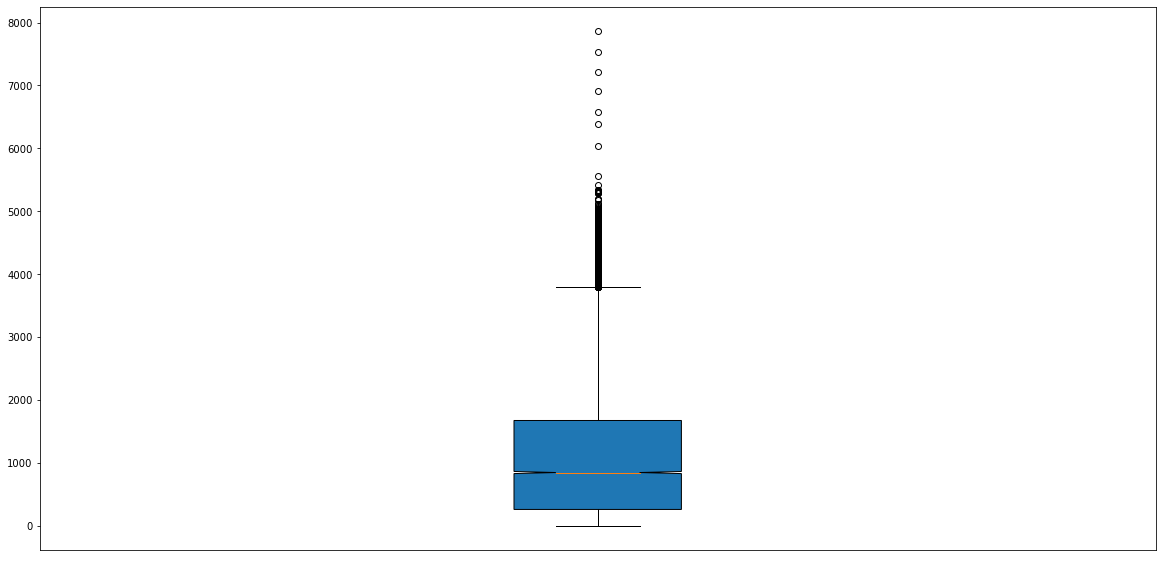

In [9]:
data= [bikesharing['cnt']]
fig, axes = plt.subplots(nrows=1,  figsize=(20, 10))
# Box plot: Notch Shape
bplot=axes.boxplot(data,notch=True, vert=True, patch_artist=True) 
# Xtick labels
plt.setp(axes, xticks=[y for y in range(len(data))],
         xticklabels=['count'])


plt.show()

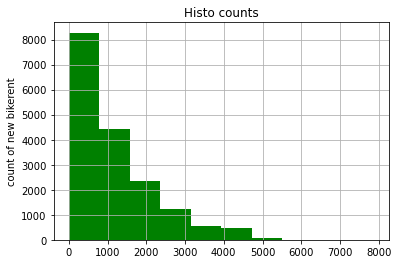

In [10]:
# the histogram of the data
plt.hist(bikesharing['cnt'], density=False, facecolor='green',label='count')


#plt.xlabel('')
plt.ylabel('count of new bikerent')
plt.title('Histo counts')


plt.grid(True)

plt.show()

### Real temperature vs. feeling temperatur


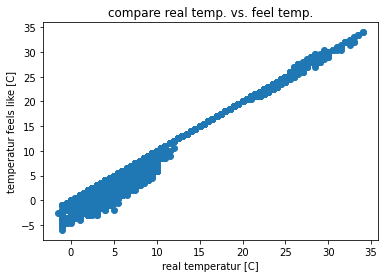

In [737]:
fig, axis = plt.subplots()
axis.scatter(bikesharing['t1'],bikesharing['t2'])
plt.xlabel('real temperatur [C]')
plt.ylabel('temperatur feels like [C]')
plt.title('compare real temp. vs. feel temp.')
plt.show()

# Data Preperation

In [233]:
#Spalten hinzufügen
bikesharing['date_str']='2000-01-01'
bikesharing['time_str']='00:00:00'
bikesharing['date']=pd.to_datetime('2000-01-01').date()
bikesharing['time']=pd.to_datetime('00:00:00').time()
bikesharing['year']=2000
bikesharing['month']=1
bikesharing['day']=1
bikesharing['hour']=0
bikesharing.head()


,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season,date,time,date_str,time_str,year,month,day,hour
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0,2000-01-01,00:00:00,2000-01-01,00:00:00,2000,1,1,0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0,2000-01-01,00:00:00,2000-01-01,00:00:00,2000,1,1,0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0,2000-01-01,00:00:00,2000-01-01,00:00:00,2000,1,1,0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0,2000-01-01,00:00:00,2000-01-01,00:00:00,2000,1,1,0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0,2000-01-01,00:00:00,2000-01-01,00:00:00,2000,1,1,0


In [238]:
#Split timestamp in date and time
for i in bikesharing.index:
    bikesharing['date_str'][i],bikesharing['time_str'][i] = str.split(bikesharing['timestamp'][i])
    bikesharing['date'][i]= pd.to_datetime(bikesharing['date_str'][i]).date()
    bikesharing['time'][i] = pd.to_datetime(bikesharing['time_str'][i]).time()
    bikesharing['year'][i]= pd.to_numeric(bikesharing['date_str'][i][:4])
    bikesharing['month'][i]= pd.to_numeric(bikesharing['date_str'][i][5:7])
    bikesharing['day'][i]= pd.to_numeric(bikesharing['date_str'][i][8:10])
    bikesharing['hour'][i]=pd.to_numeric(bikesharing['time_str'][i][:2])
    
    

<ipython-input-238-87a5aa17115e>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bikesharing['date_str'][i],bikesharing['time_str'][i] = str.split(bikesharing['timestamp'][i])
<ipython-input-238-87a5aa17115e>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bikesharing['date'][i]= pd.to_datetime(bikesharing['date_str'][i]).date()
<ipython-input-238-87a5aa17115e>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bikesharing['time'][i] =

In [242]:
bikesharing.head(7)


,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season,date,time,date_str,time_str,year,month,day,hour
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0,2015-01-04,00:00:00,2015-01-04,00:00:00,2015,1,4,0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0,2015-01-04,01:00:00,2015-01-04,01:00:00,2015,1,4,1
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0,2015-01-04,02:00:00,2015-01-04,02:00:00,2015,1,4,2
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0,2015-01-04,03:00:00,2015-01-04,03:00:00,2015,1,4,3
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0,2015-01-04,04:00:00,2015-01-04,04:00:00,2015,1,4,4
5,2015-01-04 05:00:00,46,2.0,2.0,93.0,4.0,1.0,0.0,1.0,3.0,2015-01-04,05:00:00,2015-01-04,05:00:00,2015,1,4,5
6,2015-01-04 06:00:00,51,1.0,-1.0,100.0,7.0,4.0,0.0,1.0,3.0,2015-01-04,06:00:00,2015-01-04,06:00:00,2015,1,4,6


array([[<AxesSubplot:title={'center':'cnt'}>,
        <AxesSubplot:title={'center':'t1'}>,
        <AxesSubplot:title={'center':'t2'}>,
        <AxesSubplot:title={'center':'hum'}>],
       [<AxesSubplot:title={'center':'wind_speed'}>,
        <AxesSubplot:title={'center':'weather_code'}>,
        <AxesSubplot:title={'center':'is_holiday'}>,
        <AxesSubplot:title={'center':'is_weekend'}>],
       [<AxesSubplot:title={'center':'season'}>,
        <AxesSubplot:title={'center':'year'}>,
        <AxesSubplot:title={'center':'month'}>,
        <AxesSubplot:title={'center':'day'}>],
       [<AxesSubplot:title={'center':'hour'}>, <AxesSubplot:>,
        <AxesSubplot:>, <AxesSubplot:>]], dtype=object)

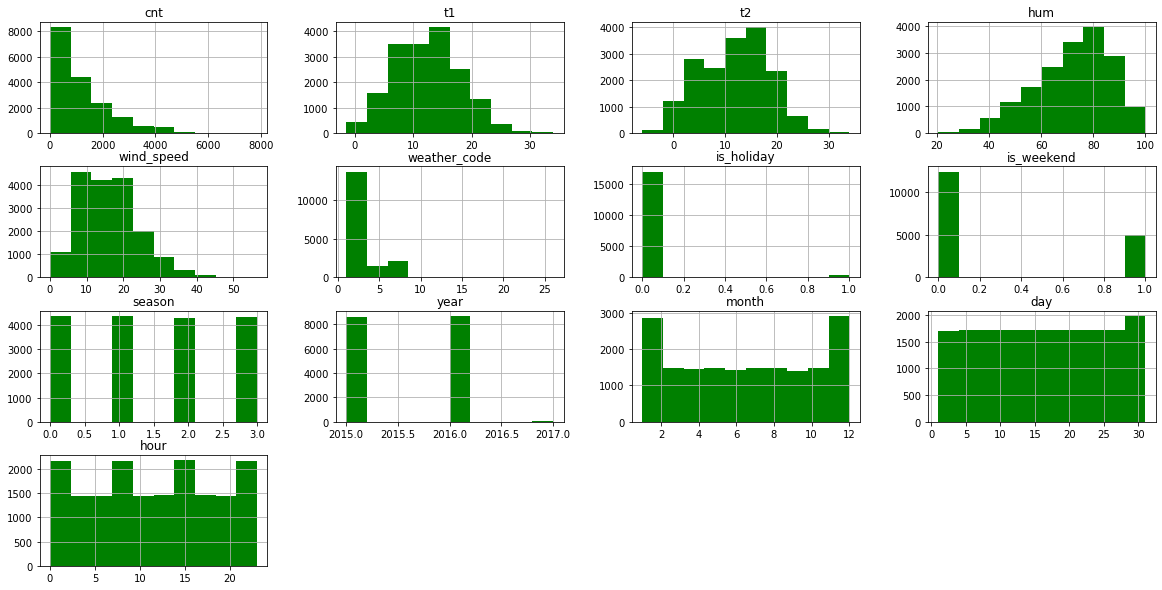

In [446]:
bikesharing.hist( density=False, facecolor='green', figsize=(20,10))


In [453]:
old_bikesharing=bikesharing.copy()

In [734]:
bikesharing=old_bikesharing#[(bikesharing['cnt']>700)]#&(old_bikesharing['cnt']<4000)]

In [735]:
bikesharing.describe()

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season,year,month,day,hour
count,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000
mean,1143.101642,12.468091,11.520836,72.324954,15.913063,2.722752,0.022051,0.285403,1.492075,2015.507810,6.514643,15.751981,11.513265
std,1085.108068,5.571818,6.615145,14.313186,7.894570,2.341163,0.146854,0.451619,1.118911,0.508157,3.452509,8.793704,6.915893
min,0.000000,-1.500000,-6.000000,20.500000,0.000000,1.000000,0.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000
25%,257.000000,8.000000,6.000000,63.000000,10.000000,1.000000,0.000000,0.000000,0.000000,2015.000000,4.000000,8.000000,6.000000
50%,844.000000,12.500000,12.500000,74.500000,15.000000,2.000000,0.000000,0.000000,1.000000,2016.000000,7.000000,16.000000,12.000000
75%,1671.750000,16.000000,16.000000,83.000000,20.500000,3.000000,0.000000,1.000000,2.000000,2016.000000,10.000000,23.000000,18.000000
max,7860.000000,34.000000,34.000000,100.000000,56.500000,26.000000,1.000000,1.000000,3.000000,2017.000000,12.000000,31.000000,23.000000


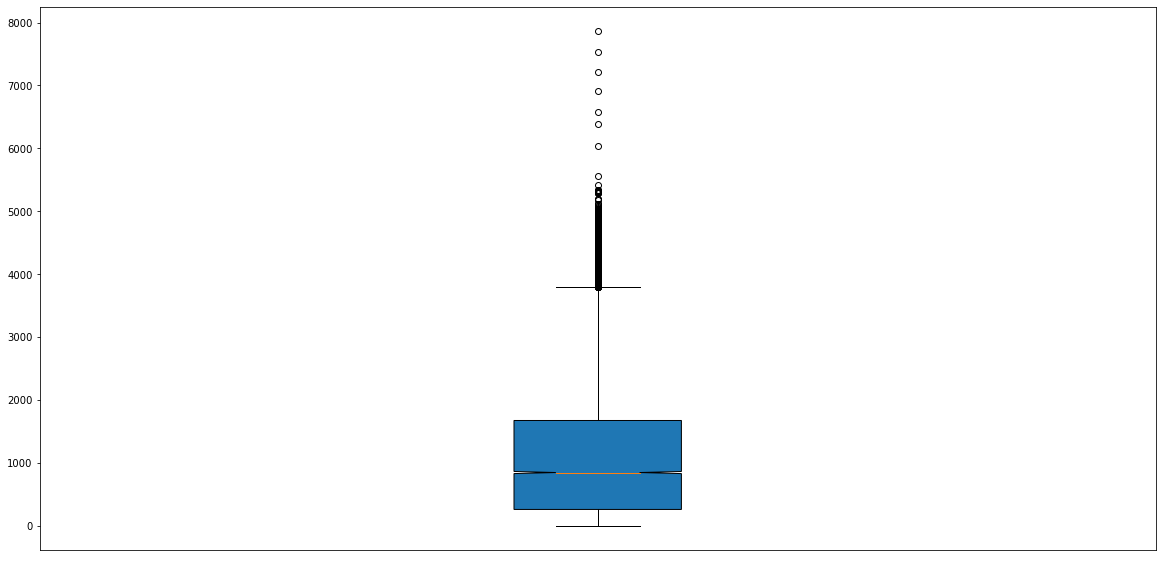

In [736]:
data= [bikesharing['cnt']]
fig, axes = plt.subplots(nrows=1,  figsize=(20, 10))
# Box plot: Notch Shape
bplot=axes.boxplot(data,notch=True, vert=True, patch_artist=True) 
# Xtick labels
plt.setp(axes, xticks=[y for y in range(len(data))],
         xticklabels=['count'])


plt.show()

# Plot the data with diferent filters


## per season

In [738]:
spring = bikesharing[bikesharing['season'].isin([0])]
summer = bikesharing[bikesharing['season'].isin([1])]
fall = bikesharing[bikesharing['season'].isin([2])]
winter = bikesharing[bikesharing['season'].isin([3])]

In [739]:
spring.head()

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season,date,time,date_str,time_str,year,month,day,hour,daytime
1342,2015-03-01 00:00:00,272,11.5,11.5,85.0,28.0,3.0,0.0,1.0,0.0,2015-03-01,00:00:00,2015-03-01,00:00:00,2015,3,1,0,
1343,2015-03-01 01:00:00,226,11.0,11.0,77.0,29.0,3.0,0.0,1.0,0.0,2015-03-01,01:00:00,2015-03-01,01:00:00,2015,3,1,1,
1344,2015-03-01 02:00:00,177,10.5,8.5,67.0,37.0,3.0,0.0,1.0,0.0,2015-03-01,02:00:00,2015-03-01,02:00:00,2015,3,1,2,
1345,2015-03-01 03:00:00,168,9.5,6.0,69.0,29.5,2.0,0.0,1.0,0.0,2015-03-01,03:00:00,2015-03-01,03:00:00,2015,3,1,3,
1346,2015-03-01 04:00:00,81,9.0,5.5,68.5,26.0,2.0,0.0,1.0,0.0,2015-03-01,04:00:00,2015-03-01,04:00:00,2015,3,1,4,


In [740]:
season_data= pd.DataFrame({'sum' : pd.Series([spring['cnt'].sum(), summer['cnt'].sum(), fall['cnt'].sum(), winter['cnt'].sum()],
                          # 'mean': pd.Series([spring['cnt'].mean(),summer['cnt'].mean(),fall['cnt'].mean(),winter['cnt'].mean()],                 
                                            index=['spring','summer','fall','winter']) }
                         )

season_data['mean']=100
season_data['mean']['winter']=winter['cnt'].mean()
season_data['mean']['spring']=spring['cnt'].mean()
season_data['mean']['summer']=summer['cnt'].mean()
season_data['mean']['fall']=fall['cnt'].mean()
print(season_data)

            sum  mean
spring  4850236  1103
summer  6424609  1464
fall    5073040  1178
winter  3558087   821


Text(0, 0.5, 'count of rents')

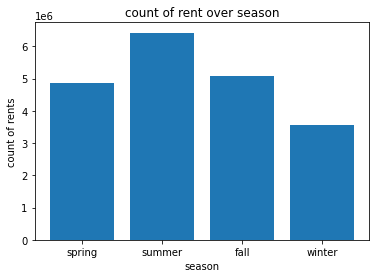

In [741]:
plt.bar(season_data.index,season_data['sum'].values)
plt.title('count of rent over season')
plt.xlabel('season')
plt.ylabel('count of rents')

## weekend and holiday (freetime)

In [742]:
weekend = bikesharing[bikesharing['is_weekend'].isin([1])]
no_weekend = bikesharing[bikesharing['is_weekend'].isin([0])]
holiday = bikesharing[bikesharing['is_holiday'].isin([1])]
no_holiday = bikesharing[bikesharing['is_holiday'].isin([0])]
weekend_holiday = weekend[weekend['is_holiday'].isin([1])]
weekend_no_holiday = weekend[weekend['is_holiday'].isin([0])]
no_weekend_holiday = no_weekend[no_weekend['is_holiday'].isin([1])]
no_weekend_no_holiday = no_weekend[no_weekend['is_holiday'].isin([0])]



In [743]:
freetime_data= pd.DataFrame({'sum': 
                             pd.Series([weekend['cnt'].sum(),no_weekend['cnt'].sum(),holiday['cnt'].sum(),no_holiday['cnt'].sum(),weekend_holiday['cnt'].sum(),weekend_no_holiday['cnt'].sum(),no_weekend_holiday['cnt'].sum(),no_weekend_no_holiday['cnt'].sum()], 
                            index=
                            ['weekend','no_weekend','holiday','no_holiday','weekend_holiday','weekend_no_holiday','no_weekend_holiday','no_weekend_no_holiday',])})

print(freetime_data)

                            sum
weekend                 4857756
no_weekend             15048216
holiday                  295498
no_holiday             19610474
weekend_holiday               0
weekend_no_holiday      4857756
no_weekend_holiday       295498
no_weekend_no_holiday  14752718


In [744]:
no_weekend.describe

<bound method NDFrame.describe of                  timestamp   cnt   t1   t2   hum  wind_speed  weather_code  \
24     2015-01-05 00:00:00    83  4.0  3.0  93.0         6.0           4.0   
25     2015-01-05 01:00:00    67  4.0  3.5  93.0         5.0           4.0   
26     2015-01-05 02:00:00    32  5.0  4.0  87.0         6.0           4.0   
27     2015-01-05 03:00:00    22  6.0  4.5  84.0         7.5           4.0   
28     2015-01-05 04:00:00    38  6.5  5.0  84.0         8.0           4.0   
...                    ...   ...  ...  ...   ...         ...           ...   
17409  2017-01-03 19:00:00  1042  5.0  1.0  81.0        19.0           3.0   
17410  2017-01-03 20:00:00   541  5.0  1.0  81.0        21.0           4.0   
17411  2017-01-03 21:00:00   337  5.5  1.5  78.5        24.0           4.0   
17412  2017-01-03 22:00:00   224  5.5  1.5  76.0        23.0           4.0   
17413  2017-01-03 23:00:00   139  5.0  1.0  76.0        22.0           2.0   

       is_holiday  is_weekend

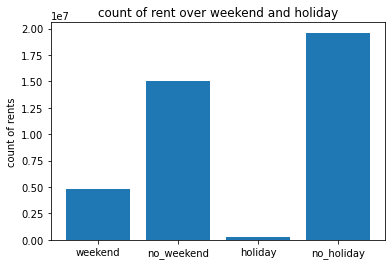

In [1195]:
plt.bar(freetime_data.index[:4],freetime_data['sum'][:4].values)
plt.title('count of rent over weekend and holiday')
#plt.xlabel('')
plt.ylabel('count of rents');

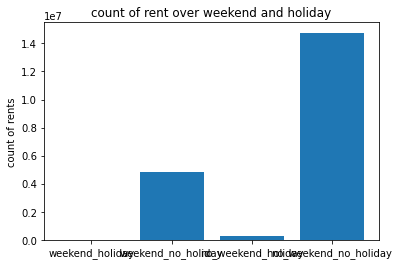

In [1196]:
plt.bar(freetime_data.index[4:],freetime_data['sum'][4:].values)
plt.title('count of rent over weekend and holiday')
#plt.xlabel('')
plt.ylabel('count of rents');

In [1198]:
holiday

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season,date,time,date_str,time_str,year,month,day,hour,daytime
2129,2015-04-03 00:00:00,279,8.0,6.0,82.0,10.0,7.0,1.0,0.0,0.0,2015-04-03,00:00:00,2015-04-03,00:00:00,2015,4,3,0,
2130,2015-04-03 01:00:00,174,8.0,5.5,79.0,14.0,7.0,1.0,0.0,0.0,2015-04-03,01:00:00,2015-04-03,01:00:00,2015,4,3,1,
2131,2015-04-03 02:00:00,89,7.5,5.5,84.5,12.0,7.0,1.0,0.0,0.0,2015-04-03,02:00:00,2015-04-03,02:00:00,2015,4,3,2,
2132,2015-04-03 03:00:00,61,7.0,5.0,87.0,11.0,7.0,1.0,0.0,0.0,2015-04-03,03:00:00,2015-04-03,03:00:00,2015,4,3,3,
2133,2015-04-03 04:00:00,46,7.0,6.0,93.0,6.0,7.0,1.0,0.0,0.0,2015-04-03,04:00:00,2015-04-03,04:00:00,2015,4,3,4,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17385,2017-01-02 19:00:00,433,3.0,0.0,81.0,11.0,1.0,1.0,0.0,3.0,2017-01-02,19:00:00,2017-01-02,19:00:00,2017,1,2,19,
17386,2017-01-02 20:00:00,334,3.0,0.0,75.0,13.0,1.0,1.0,0.0,3.0,2017-01-02,20:00:00,2017-01-02,20:00:00,2017,1,2,20,
17387,2017-01-02 21:00:00,233,2.5,-0.5,78.0,11.0,1.0,1.0,0.0,3.0,2017-01-02,21:00:00,2017-01-02,21:00:00,2017,1,2,21,
17388,2017-01-02 22:00:00,201,2.0,-1.0,81.0,10.0,1.0,1.0,0.0,3.0,2017-01-02,22:00:00,2017-01-02,22:00:00,2017,1,2,22,


## weather 

In [748]:
clear =bikesharing[bikesharing['weather_code'].isin([1])]
fewClouds= bikesharing[bikesharing['weather_code'].isin([2])]
brokenClouds = bikesharing[bikesharing['weather_code'].isin([3])]
cloudy = bikesharing[bikesharing['weather_code'].isin([4])]
rain = bikesharing[bikesharing['weather_code'].isin([7])]
rain_thunderstorm = bikesharing[bikesharing['weather_code'].isin([10])]
snow = bikesharing[bikesharing['weather_code'].isin([26])]
freezing = bikesharing[bikesharing['weather_code'].isin([94])]

In [749]:
weather_code_data= pd.DataFrame({'sum': 
                             pd.Series([clear['cnt'].sum(),fewClouds['cnt'].sum(),brokenClouds['cnt'].sum(),cloudy['cnt'].sum(),rain['cnt'].sum(),rain_thunderstorm['cnt'].sum(),snow['cnt'].sum(),freezing['cnt'].sum()], 
                            index=
                            ['clear','fewClouds','brokenClouds','cloudy','rain','rain and thunderstorm','snow','freezing',])})

print(weather_code_data)

                           sum
clear                  7146847
fewClouds              6035580
brokenClouds           4243887
cloudy                  929978
rain                   1526461
rain and thunderstorm     8168
snow                     15051
freezing                     0


Text(0, 0.5, 'count of rents')

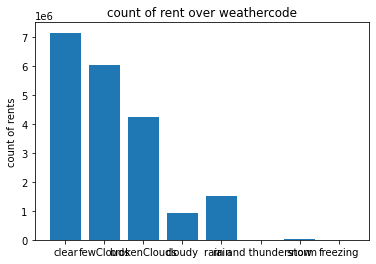

In [750]:
plt.bar(weather_code_data.index,weather_code_data['sum'].values)
plt.title('count of rent over weathercode')
#plt.xlabel('')
plt.ylabel('count of rents')

### over temperature

In [1163]:
temp_real_Rent=bikesharing.groupby('t1')['cnt'].median()
temp_feel_Rent=bikesharing.groupby('t2')['cnt'].median()
hum_Rent =bikesharing.groupby('hum')['cnt'].median()
wind_Rent=bikesharing.groupby('wind_speed')['cnt'].median()

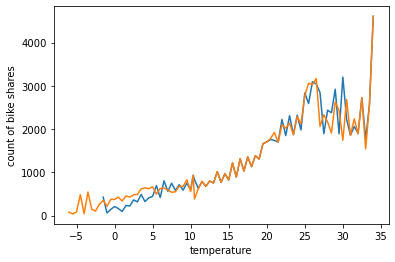

In [1164]:
plt.plot(temp_real_Rent.index, temp_real_Rent)
plt.plot(temp_feel_Rent.index, temp_feel_Rent)

#Label the axes
plt.xlabel('temperature')
plt.ylabel('count of bike shares')

plt.show()

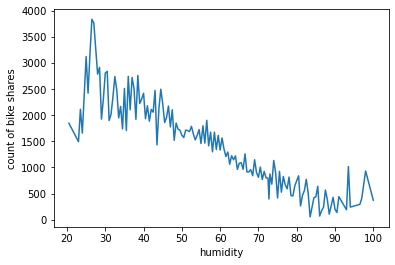

In [1165]:

plt.plot(hum_Rent.index, hum_Rent)

#Label the axes
plt.xlabel('humidity')
plt.ylabel('count of bike shares')

plt.show()

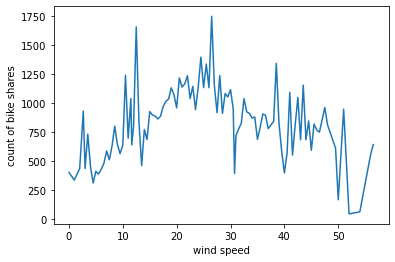

In [754]:
plt.plot(wind_Rent.index, wind_Rent)

#Label the axes
plt.xlabel('wind speed')
plt.ylabel('count of bike shares')

plt.show()

## over time

In [755]:
dailyRent=bikesharing.groupby('date')['cnt'].sum()

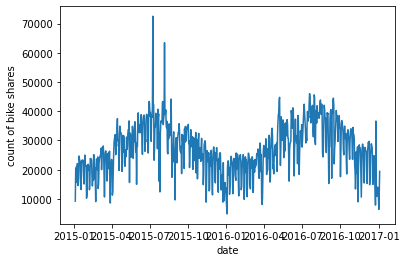

In [756]:
plt.plot(dailyRent.index, dailyRent)

#Label the axes
plt.xlabel('date')
plt.ylabel('count of bike shares')

#label the figure plt.title('New bike shares over time')
#plt.axis([1959, 2011,0,25])
plt.show()

## by month


In [757]:
monthlyRent=bikesharing.groupby('month')['cnt'].sum()

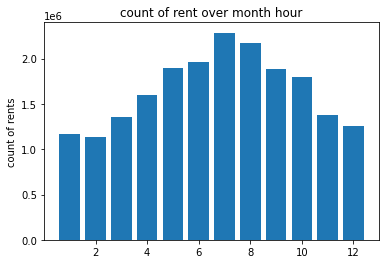

In [758]:
plt.bar(monthlyRent.index,monthlyRent)
plt.title('count of rent over month hour')
#plt.xlabel('')
plt.ylabel('count of rents')
plt.show()

## by hour

In [759]:
hourlyRent=bikesharing.groupby('hour')['cnt'].sum()
#hourlyRent

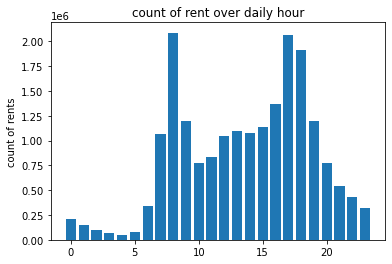

In [760]:
plt.bar(hourlyRent.index,hourlyRent)
plt.title('count of rent over daily hour')
#plt.xlabel('')
plt.ylabel('count of rents')
plt.show()

## per daytime

night: 21:00-5:00
morning: 5:00-10:00
daytime: 10:00-16:00
evening: 16:00-21:00

In [761]:
bikesharing['daytime']=''

In [762]:
for i in bikesharing.index:
    if bikesharing['hour']<6 or bikesharing['hour']>21:
        bikesharing['daytime'][i]= 'night'
    else:
        if bikesharing['hour']<10:
            bikesharing['daytime'][i]= 'morning'
        else:
            if bikesharing['hour']<16:
            bikesharing['daytime'][i]= 'daytime'
            

IndentationError: expected an indented block (<ipython-input-762-0873a70d2a59>, line 9)

## first finding
-In winter there are not that many rents than in the other seasons, the most rents are in summer
-The most rents are on none holyday and on weekdays
-The most rents are on good weather. By cloudy and rainy weather are significant lesser rents. By snowfall or freezing temperatures are only a few rents
-the most rents are between 7 an 10 oclock in the morning and between 17 an 19 oclock in the evening
-if the temperatur gets higher there ar more rents
- if the humidity gets lower then there are more rents


## combine the filter


In [763]:
hour_weekend=weekend.groupby('hour')['cnt'].median()
hour_no_weekend=no_weekend.groupby('hour')['cnt'].median()


### weekend + daytime

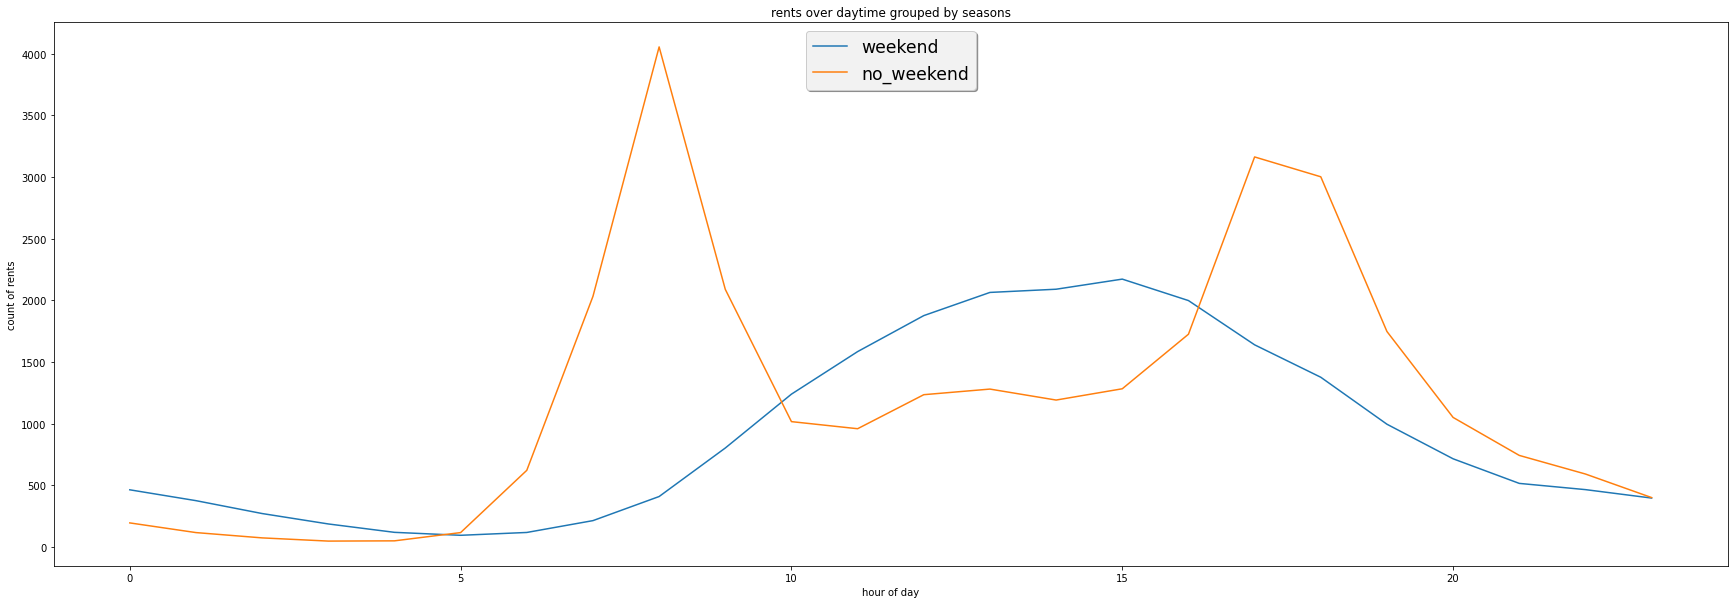

In [764]:
fig, ax = plt.subplots(figsize=(30, 10))
ax.set_title('rents over daytime grouped by seasons')
ax.set_xlabel('hour of day',fontsize=10)
ax.set_ylabel('count of rents',fontsize=10)

ax.plot(hour_weekend.index,hour_weekend,label='weekend')
ax.plot(hour_no_weekend.index,hour_no_weekend,label='no_weekend')


# Add the legend
legend = plt.legend(loc = 'upper center', 
                    shadow=True,
                    prop={'weight':'roman','size':'xx-large'})

frame = legend.get_frame()
frame.set_facecolor('.95')
plt.show()

### season + daytime

In [765]:
hour_winter=winter.groupby('hour')['cnt'].median()
hour_spring=spring.groupby('hour')['cnt'].median()
hour_summer=summer.groupby('hour')['cnt'].median()
hour_fall=fall.groupby('hour')['cnt'].median()

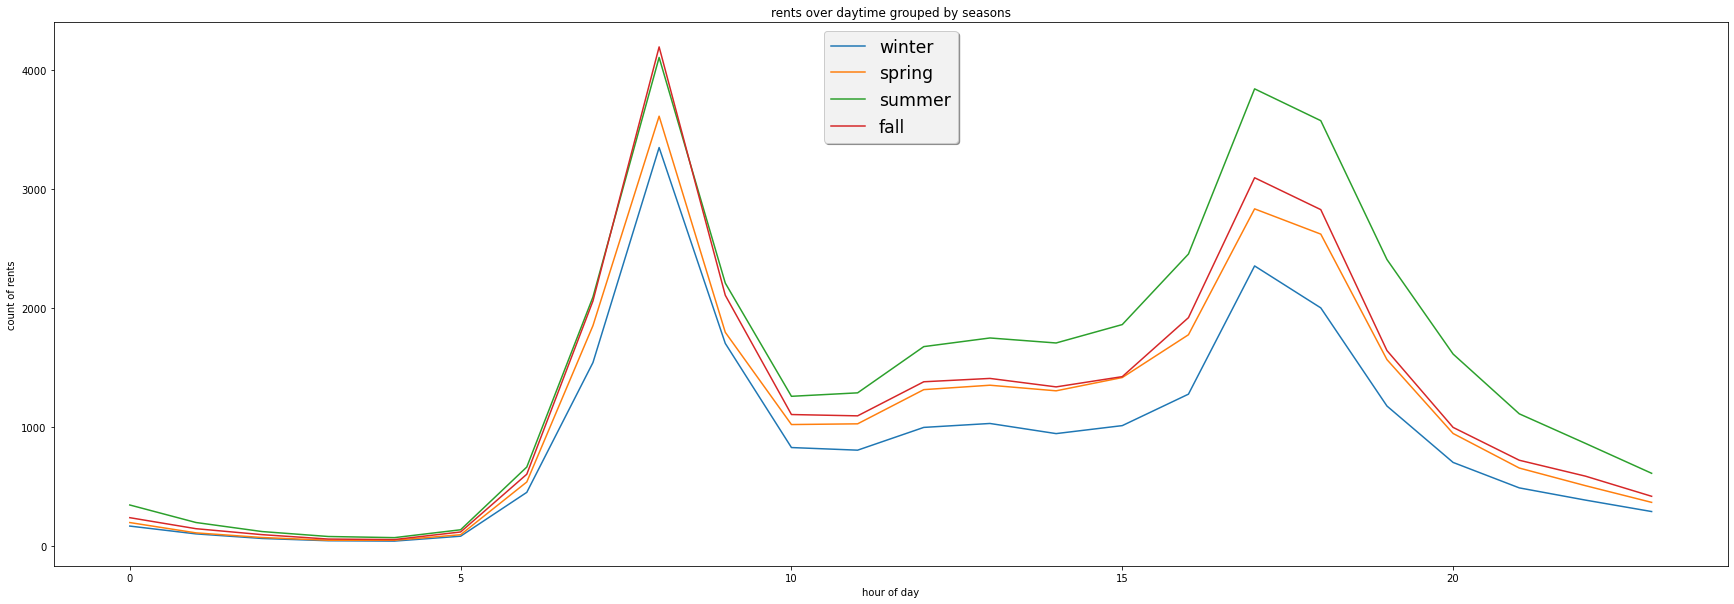

In [766]:
fig, ax = plt.subplots(figsize=(30, 10))
ax.set_title('rents over daytime grouped by seasons')
ax.set_xlabel('hour of day',fontsize=10)
ax.set_ylabel('count of rents',fontsize=10)

ax.plot(hour_winter.index,hour_winter,label='winter')
ax.plot(hour_spring.index,hour_spring,label='spring')
ax.plot(hour_summer.index,hour_summer,label='summer')
ax.plot(hour_fall.index,hour_fall,label='fall')

# Add the legend
legend = plt.legend(loc = 'upper center', 
                    shadow=True,
                    prop={'weight':'roman','size':'xx-large'})

frame = legend.get_frame()
frame.set_facecolor('.95')
plt.show()

### weahter + daytime

In [767]:
hour_clear=clear.groupby('hour')['cnt'].median()
hour_fewClouds=fewClouds.groupby('hour')['cnt'].median()
hour_brokenClouds=brokenClouds.groupby('hour')['cnt'].median()
hour_cloudy=cloudy.groupby('hour')['cnt'].median()
hour_rain=rain.groupby('hour')['cnt'].median()

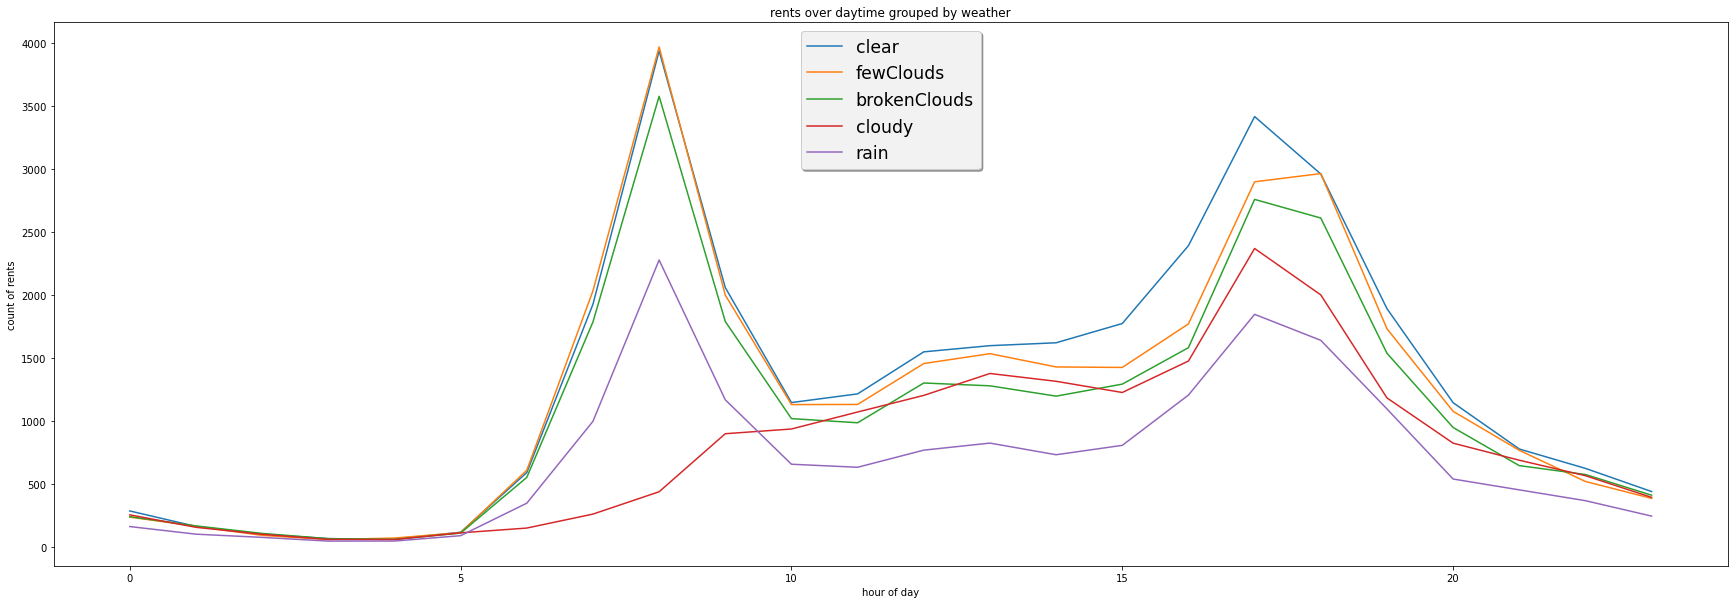

In [768]:
fig, ax = plt.subplots(figsize=(30, 10))
ax.set_title('rents over daytime grouped by weather')
ax.set_xlabel('hour of day',fontsize=10)
ax.set_ylabel('count of rents',fontsize=10)

ax.plot(hour_clear.index,hour_clear,label='clear')
ax.plot(hour_fewClouds.index,hour_fewClouds,label='fewClouds')
ax.plot(hour_brokenClouds.index,hour_brokenClouds,label='brokenClouds')
ax.plot(hour_cloudy.index,hour_cloudy,label='cloudy')
ax.plot(hour_rain.index,hour_rain,label='rain')

# Add the legend
legend = plt.legend(loc = 'upper center', 
                    shadow=True,
                    prop={'weight':'roman','size':'xx-large'})

frame = legend.get_frame()
frame.set_facecolor('.95')
plt.show()

# finding
-the 

# Prediction of bikerents

In [982]:
bikesharing.columns


Index(['timestamp', 'cnt', 't1', 't2', 'hum', 'wind_speed', 'weather_code',
       'is_holiday', 'is_weekend', 'season', 'date', 'time', 'date_str',
       'time_str', 'year', 'month', 'day', 'hour', 'daytime', 'class'],
      dtype='object')

In [1007]:
bikesharingPred=bikesharing.copy()


In [1094]:
features=['t1','t2','hum', 'wind_speed', 'weather_code','is_weekend', 'is_holiday', 'season','month', 'day', 'hour']
target =['cnt']


In [1095]:
X=bikesharingPred[features]
y=bikesharingPred[target]

In [1096]:
#splite data into Training an Test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=324)

## Linear Regression


In [1097]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [1098]:
y_prediction = regressor.predict(X_test)
y_prediction

array([[1644.47481647],
       [ 129.72187381],
       [2462.87353235],
       ...,
       [ 956.84641455],
       [ 328.4749017 ],
       [ 679.96273341]])

In [1099]:
#Evaluate Linear Regression
RMSE = sqrt(mean_squared_error(y_true = y_test, y_pred = y_prediction))
print (RMSE)

909.0298875949703


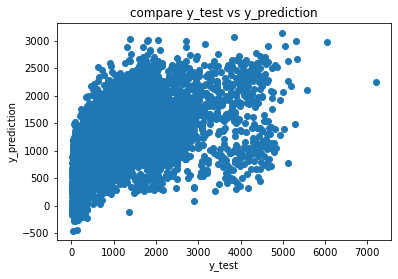

In [1100]:
fig, axis = plt.subplots()
axis.scatter(y_test,y_prediction)
plt.xlabel('y_test')
plt.ylabel('y_prediction')
plt.title('compare y_test vs y_prediction')
plt.show()

## Decision Tree Regressor 

In [1101]:
regressor = DecisionTreeRegressor(max_depth=11)
regressor.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=11)

In [1102]:
y_prediction = regressor.predict(X_test)
y_prediction

array([2359.05454545,  121.25      , 1745.35666667, ...,  195.58      ,
       1758.98529412,  950.94249201])

In [1103]:
#Evaluate Decision Tree Regression
RMSE = sqrt(mean_squared_error(y_true = y_test, y_pred = y_prediction))
print (RMSE)

295.2338017179411


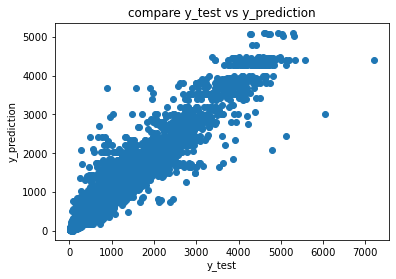

In [1104]:
fig, axis = plt.subplots()
axis.scatter(y_test,y_prediction)
plt.xlabel('y_test')
plt.ylabel('y_prediction')
plt.title('compare y_test vs y_prediction')
plt.show()

## Clustering

In [1183]:
features_c=['cnt','t1','hum', 'wind_speed', 'weather_code','is_weekend', 'is_holiday', 'season','month', 'day', 'hour']
Xc=StandardScaler().fit_transform(bikesharingPred[features_c])
Xc

array([[-0.88574518, -1.69933106,  1.44451693, ..., -1.59733173,
        -1.33644696, -1.66480245],
       [-0.9262953 , -1.69933106,  1.44451693, ..., -1.59733173,
        -1.33644696, -1.52020381],
       [-0.92998167, -1.78907097,  1.68905371, ..., -1.59733173,
        -1.33644696, -1.37560517],
       ...,
       [-0.74289816, -1.25063156,  0.43143596, ..., -1.59733173,
        -1.45016795,  1.37176892],
       [-0.84703824, -1.25063156,  0.25676683, ..., -1.59733173,
        -1.45016795,  1.51636755],
       [-0.92537371, -1.34037146,  0.25676683, ..., -1.59733173,
        -1.45016795,  1.66096619]])

In [1184]:
kmeans = KMeans(n_clusters=3)
model = kmeans.fit(X)
print("model\n", model)

model
 KMeans(n_clusters=3)


In [1185]:
centers = model.cluster_centers_
centers

array([[1.00146964e+01, 8.93660639e+00, 8.54223584e+01, 1.15391322e+01,
        3.36153041e+00, 2.90091167e-01, 2.74996264e-02, 1.73471828e+00,
        6.77701390e+00, 1.47765655e+01, 8.42400239e+00],
       [1.19830946e+01, 1.08101719e+01, 7.11550501e+01, 1.87665115e+01,
        2.62521490e+00, 2.91690544e-01, 2.06303725e-02, 1.56704871e+00,
        6.35659026e+00, 1.67174785e+01, 1.26355301e+01],
       [1.77582153e+01, 1.74656692e+01, 5.10936415e+01, 1.84107668e+01,
        1.76275715e+00, 2.65295218e-01, 1.49612610e-02, 9.18514561e-01,
        6.34036869e+00, 1.56951643e+01, 1.49428266e+01]])

In [1186]:
# Function that creates a DataFrame with a column for Cluster Number

def pd_centers(featuresUsed, centers):
	colNames = list(featuresUsed)
	colNames.append('prediction')

	# Zip with a column called 'prediction' (index)
	Z = [np.append(A, index) for index, A in enumerate(centers)]

	# Convert to pandas data frame for plotting
	P = pd.DataFrame(Z, columns=colNames)
	P['prediction'] = P['prediction'].astype(int)
	return P

In [1192]:
# Function that creates Parallel Plots

def parallel_plot(data):
	my_colors = list(islice(cycle(['b', 'r', 'g', 'y', 'k']), None, len(data)))
	plt.figure(figsize=(15,8)).gca().axes.set_ylim([-3,25])
	parallel_coordinates(data, 'prediction', color = my_colors, marker='o')

In [1193]:
P = pd_centers(features_c, centers)
P

,cnt,t1,hum,wind_speed,weather_code,is_weekend,is_holiday,season,month,day,hour,prediction
0,10.014696,8.936606,85.422358,11.539132,3.361530,0.290091,0.027500,1.734718,6.777014,14.776566,8.424002,0
1,11.983095,10.810172,71.155050,18.766511,2.625215,0.291691,0.020630,1.567049,6.356590,16.717479,12.635530,1
2,17.758215,17.465669,51.093641,18.410767,1.762757,0.265295,0.014961,0.918515,6.340369,15.695164,14.942827,2


In [1]:
parallel_plot(P[P['cnt'] >2000] )

NameError: name 'parallel_plot' is not defined